# Lesson 7 · Deep-Learning Forecasting: RNN, LSTM, GRU & Transformers
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 15** &nbsp;|&nbsp; ⏱ ≈ 130 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Prepare **sequence windows** (batch × time × features) without leaking the future
> - Explain how **RNN, LSTM and GRU** process sequences, and why gates fix the **vanishing-gradient** problem
> - Explain **self-attention** and build a small **Transformer** forecaster
> - Train PyTorch models with **early stopping, gradient clipping and fixed seeds**
> - Evaluate neural forecasters with **walk-forward** validation and judge them *honestly* against XGBoost and naive

**Prerequisites:** Lessons 3 and 6; basic PyTorch ideas from earlier phases (tensors, `nn.Module`, optimisers).

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 1 · The honest introduction to deep learning for forecasting

Neural networks dominate images, speech and text. For **time series**, the story is more nuanced, and a good professor tells you the truth:

| | Deep learning shines when… | …but be careful when |
|---|---|---|
| Data | you have *thousands* of series or *very long* histories | you have **one series with ~600 points** (our situation) |
| Structure | patterns are complex, non-linear, interacting | a seasonal + trend + drivers model already explains most of it |
| Effort | you want a model that learns its own features from raw sequences | you need interpretability, intervals, fast iteration |

Published benchmarks repeatedly show that on small single-series data, tuned **ETS / ARIMA / gradient boosting** are *very* hard to beat, and that simple linear models can rival fancy Transformers. We study neural forecasters anyway because
(1) they are the foundation of modern *global* models trained across many series (and "foundation models" for time series), and
(2) **you must know how to evaluate them honestly**. Expect to see them compete, not necessarily win, here.

## 2 · Sequences as tensors: windows

A recurrent/attention network consumes a **window** of the last `L` weeks and emits the next `H` values:

```
  input X[i]   :  weeks  t-L+1 … t        shape (L, F)      F features per week
  target Y[i]  :  cumulative log-returns for h = 1 … H after t    shape (H,)
  whole batch  :  X (N, L, F),  Y (N, H)                      ← "batch_first" convention
```

As in Lesson 6 we forecast **returns** (stationary, scale-free) and rebuild the price from the latest known value. Per-week features (all known at that week):
`ret` (weekly log return), `dev_ma12`, `rain6` (6-week rainfall), `fuel`, `fest`, and four Fourier calendar terms.

> 🔑 **Where shuffling is: and isn't: allowed.** The **train/validation/test split must be chronological**. But *inside* the training set each window is self-contained, so shuffling windows for mini-batch SGD is fine. The leakage in Lesson 3 came from *evaluating* on shuffled data.

X (windows, weeks, features): (556, 52, 9)
Y (windows, horizons)       : (556, 8)
features                    : ['ret', 'dev_ma12', 'rain6', 'fuel', 'fest', 'sin1', 'cos1', 'sin2', 'cos2']
first / last origin         : 2014-03-16 / 2024-11-03


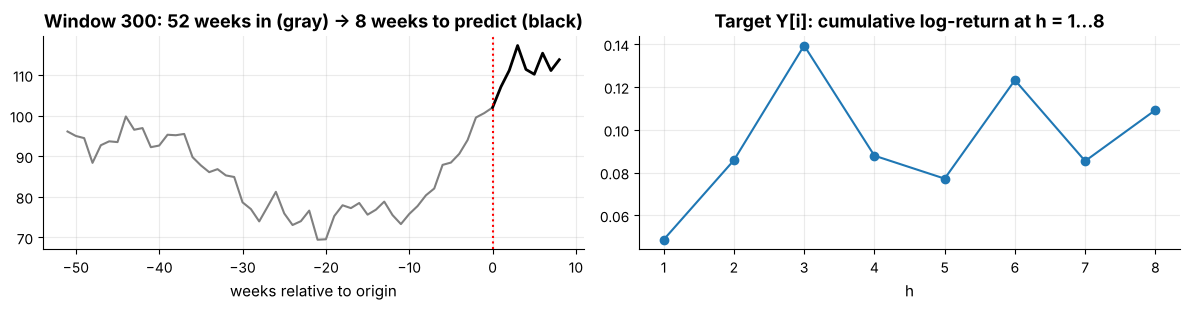

In [2]:
from dl_utils import *
import torch, torch.nn as nn, inspect

mz = load_weekly("maize")
step_feats, lp = make_step_features(mz)
X, Y, org = make_windows(step_feats, lp, L=52, H=8)
print("X (windows, weeks, features):", X.shape)
print("Y (windows, horizons)       :", Y.shape)
print("features                    :", FEATURES)
print("first / last origin         :", mz.index[org[0]].date(), "/", mz.index[org[-1]].date())

# a picture of ONE window and its target
i = 300
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(range(-51, 1), np.exp(lp.values[org[i] - 51: org[i] + 1]), color="gray")
ax[0].plot(range(0, 9), np.exp(lp.values[org[i]: org[i] + 9]), color="black", lw=2); ax[0].axvline(0, color="red", ls=":")
ax[0].set_title(f"Window {i}: 52 weeks in (gray) → 8 weeks to predict (black)"); ax[0].set_xlabel("weeks relative to origin")
ax[1].plot(range(1, 9), Y[i], marker="o"); ax[1].set_title("Target Y[i]: cumulative log-return at h = 1…8"); ax[1].set_xlabel("h")
plt.tight_layout(); plt.show()

## 3 · Recurrent Neural Networks (RNN)

An RNN reads the window **one week at a time**, carrying a **hidden state** $h_t$: a running summary of everything seen so far:

$$h_t = \tanh\!\big(W_x\,x_t + W_h\,h_{t-1} + b\big)$$

> 💡 **Analogy:** reading a novel with a single sticky note. After each page you rewrite the note using the new page and the old note. The note at the end is all you have to answer questions.

Let's make sure we truly understand it by computing the recurrence **by hand in NumPy** and comparing with PyTorch:

In [3]:
torch.manual_seed(0)
rnn = nn.RNN(input_size=2, hidden_size=3, batch_first=True)
x = torch.randn(1, 5, 2)                                   # 1 sequence, 5 time steps, 2 features
out, _ = rnn(x)

Wx, Wh, bx, bh = [p.detach().numpy() for p in (rnn.weight_ih_l0, rnn.weight_hh_l0, rnn.bias_ih_l0, rnn.bias_hh_l0)]
h = np.zeros(3)
for t in range(5):
    h = np.tanh(Wx @ x[0, t].numpy() + bx + Wh @ h + bh)  # the entire RNN is this one line, repeated
print("NumPy hidden state :", h.round(5))
print("PyTorch hidden state:", out[0, -1].detach().numpy().round(5))
print("max difference:", np.abs(h - out[0, -1].detach().numpy()).max())

NumPy hidden state : [-0.3086   0.51539  0.88947]
PyTorch hidden state: [-0.3086   0.51539  0.88947]
max difference: 3.537293880029324e-08


### The problem: vanishing gradients
To learn that *"rain 40 weeks ago matters now"*, the error signal must travel **backwards through 40 repeated multiplications** by $W_h$ and the derivative of tanh (< 1). A product of many numbers below 1 **vanishes**.
Let's *measure* it: how much does the output change if we nudge the input at week *k* of a 52-week window? (gradient size, averaged over 20 random initialisations; log scale)

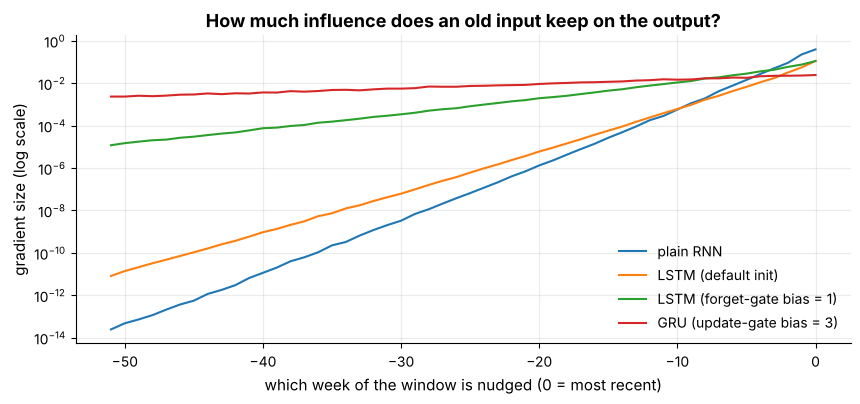

plain RNN                    influence of the week 51 steps back: 2.5e-14
LSTM (default init)          influence of the week 51 steps back: 8.2e-12
LSTM (forget-gate bias = 1)  influence of the week 51 steps back: 1.2e-05
GRU (update-gate bias = 3)   influence of the week 51 steps back: 2.3e-03


In [4]:
L, F, hid = 52, len(FEATURES), 32
def grad_profile(kind, gate_bias=None, trials=20):
    gs = []
    for seed in range(trials):
        torch.manual_seed(seed); m = build_model(kind, F, 8, L, hid, dropout=0.0).eval()
        if gate_bias is not None:                              # LSTM: forget-gate bias; GRU: update-gate bias
            with torch.no_grad(): m.rnn.bias_ih_l0[hid:2 * hid] = gate_bias
        xx = torch.randn(1, L, F, requires_grad=True); m(xx)[0].sum().backward()
        gs.append(xx.grad.norm(dim=-1)[0].numpy())
    return np.mean(gs, axis=0)

profiles = {"plain RNN": grad_profile("rnn"), "LSTM (default init)": grad_profile("lstm"),
            "LSTM (forget-gate bias = 1)": grad_profile("lstm", 1.0), "GRU (update-gate bias = 3)": grad_profile("gru", 3.0)}
fig, ax = plt.subplots(figsize=(10, 4))
for name, g in profiles.items(): ax.semilogy(range(-51, 1), g, label=name)
ax.set_xlabel("which week of the window is nudged (0 = most recent)"); ax.set_ylabel("gradient size (log scale)")
ax.set_title("How much influence does an old input keep on the output?"); ax.legend(); plt.show()
for name, g in profiles.items(): print(f"{name:<28} influence of the week 51 steps back: {g[0]:.1e}")

**Reading the plot.** For the plain RNN the influence of week −51 is about $10^{-14}$: *numerically zero*; it cannot learn long-range dependencies. With **gates initialised to "remember"** (a standard trick), the LSTM and GRU keep a usable signal back across the whole year.
(With PyTorch's *default* initialisation the LSTM is only a little better than the plain RNN at the start; its gradient still vanishes, because the gates must first be *trained* to open. Initialisation matters!)

## 4 · LSTM and GRU: gated memory

**LSTM (Long Short-Term Memory)** adds a separate **cell state** $c_t$ (a *conveyor belt* running through time) and three gates (values in 0…1) that decide what to write, erase and read:

| Gate | Question it answers |
|---|---|
| **Forget** $f_t$ | "How much of the old memory do I keep?" |
| **Input** $i_t$ | "How much of the new information do I write?" |
| **Output** $o_t$ | "How much of the memory do I reveal as the hidden state?" |

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t \qquad h_t = o_t \odot \tanh(c_t)$$

Because $c_t$ is updated *additively*, gradients can flow along the belt without being squashed: the cure for vanishing gradients.

**GRU (Gated Recurrent Unit)** is a leaner cousin: two gates (**reset**, **update**) and no separate cell state: ¾ of an LSTM's parameters, often equally accurate, quicker to train.

| | RNN | GRU | LSTM |
|---|---|---|---|
| Gates | 0 | 2 | 3 |
| Separate cell state | no | no | yes |
| Params (rel.) | 1× | 3× | 4× |
| Long memory | poor | good | good |

Here is the code of our recurrent forecaster: notice how little there is:

In [5]:
print(inspect.getsource(SeqForecaster))
for k in ["rnn", "gru", "lstm"]:
    print(f"{k:<5} parameters: {count_params(build_model(k, len(FEATURES), 8, 52, 32)):>6,}")

class SeqForecaster(nn.Module):
    """RNN / LSTM / GRU encoder + linear head that predicts H cumulative returns."""
    def __init__(self, kind, n_features, H=8, hidden=32, dropout=0.1):
        super().__init__()
        self.kind = kind
        cell = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = cell(n_features, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, H)
    def forward(self, x):
        out, _ = self.rnn(x)                    # out: (batch, L, hidden) -- hidden state at every week
        return self.head(self.drop(out[:, -1])) # use the LAST hidden state: it has "read" the whole window

rnn   parameters:  1,640
gru   parameters:  4,392
lstm  parameters:  5,768


## 5 · Transformers and self-attention

Recurrent nets read week-by-week; a **Transformer** lets *every week look at every other week at once* through **self-attention**.

> 💡 **Analogy:** a library. Each week writes a **Query** ("what am I looking for?"), a **Key** ("what do I contain?") and a **Value** ("what I'll hand over"). A week attends strongly to weeks whose keys match its query, and blends their values.

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^{\top}}{\sqrt d}\right)V$$

Since attention itself ignores order, we add a **positional embedding** telling each token *which week of the window it is*. A block = attention + a small feed-forward net, each with a residual connection and LayerNorm.

In [6]:
print(inspect.getsource(TransformerForecaster))
print("Transformer parameters:", f"{count_params(build_model('transformer', len(FEATURES), 8, 52, 32)):,}")

class TransformerForecaster(nn.Module):
    def __init__(self, n_features, H=8, L=52, d=32, heads=2, layers=2, dropout=0.1):
        super().__init__()
        self.kind = "transformer"
        self.inp = nn.Linear(n_features, d)
        self.pos = nn.Parameter(torch.zeros(1, L, d))          # learned positional embedding: "which week of the window am I?"
        nn.init.normal_(self.pos, std=0.02)
        self.blocks = nn.ModuleList([AttnBlock(d, heads, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, H)
    def forward(self, x):
        h = self.inp(x) + self.pos[:, : x.shape[1]]
        for b in self.blocks:
            h = b(h)
        return self.head(self.norm(h)[:, -1])

Transformer parameters: 19,400


> ⚠️ **Reality check.** Time-series Transformers (Informer, Autoformer, PatchTST, Temporal Fusion Transformer, …) are an active research area, and "foundation models" pretrained on millions of series (e.g. Chronos, TimesFM) can forecast **zero-shot**.
> But published ablations also found that on modest datasets a *single linear layer on the lag window* can match many Transformers. Always benchmark against the simple stuff.

## 6 · The training recipe

Look at `train_model` in `dl_utils.py`. The ingredients, each there for a reason:

| Ingredient | Purpose |
|---|---|
| **Standardise** inputs/targets with *training-window* statistics | stable optimisation, no leakage |
| **Huber (SmoothL1) loss** | robust to the odd extreme return |
| **AdamW** + weight decay | adaptive steps + regularisation |
| **Dropout** | combats over-fitting on only ~500 windows |
| **Gradient clipping** | stops exploding gradients |
| **Early stopping on a chronological validation slice** | stop when validation loss stops improving; restore the best weights |
| **Fixed random seed** | reproducibility (but see §8: seeds still matter!) |

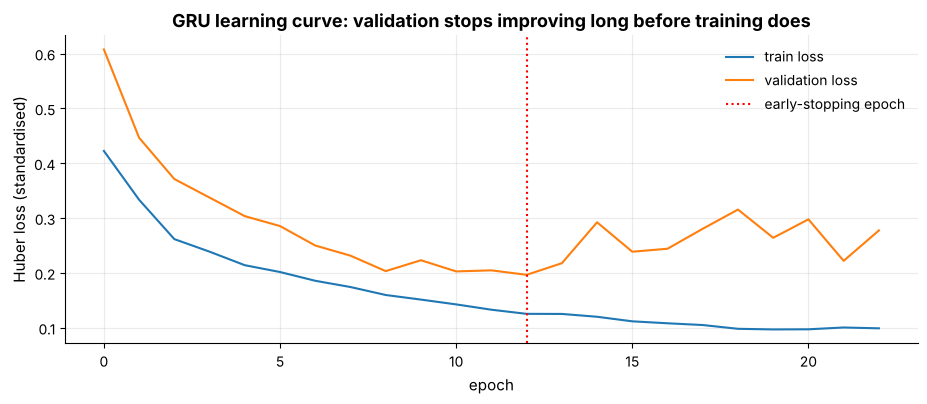

epochs run: 23 | best epoch: 12


In [7]:
t0 = 469                                                   # pretend today is week 470: only windows fully known by then
tr = org + 8 <= t0
gru, sc, hist = train_model("gru", X[tr], Y[tr], seed=0)
plt.plot(hist["train"], label="train loss"); plt.plot(hist["val"], label="validation loss")
plt.axvline(int(np.argmin(hist["val"])), color="red", ls=":", label="early-stopping epoch")
plt.xlabel("epoch"); plt.ylabel("Huber loss (standardised)"); plt.legend(); plt.title("GRU learning curve: validation stops improving long before training does"); plt.show()
print("epochs run:", len(hist["val"]), "| best epoch:", int(np.argmin(hist["val"])))

> 🩺 **Reading learning curves.** Training loss keeps falling (the net memorises its training windows) while validation loss bottoms out, then rises: **over-fitting**. Early stopping restores the weights from the validation minimum.

### What does attention look at?
Let's train a small Transformer and look at where the *last* week of the window directs its attention:

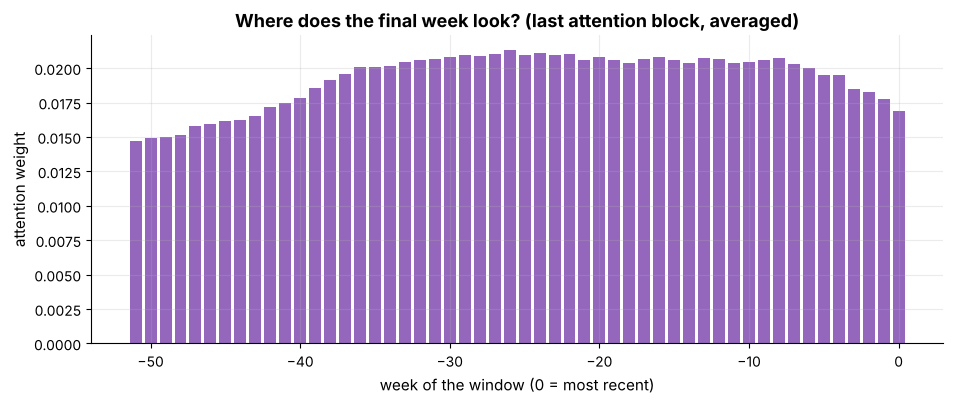

In [8]:
tf, sc_tf, _ = train_model("transformer", X[tr], Y[tr], seed=0)
tf.eval()
with torch.no_grad(): tf(torch.tensor(sc_tf.tx(X[org > t0][:64])))              # run some test windows through
attn = tf.blocks[-1].last_attn[:, -1, :].mean(0).numpy()                          # last week's attention over the 52 weeks, averaged over windows
plt.bar(range(-51, 1), attn, color="tab:purple"); plt.xlabel("week of the window (0 = most recent)"); plt.ylabel("attention weight")
plt.title("Where does the final week look? (last attention block, averaged)"); plt.show()

**What do we see?** The weights are close to uniform (≈ 1/52 ≈ 0.019 per week) with a gentle hump: after a short training run with early stopping on only ~500 windows, the model has learned little more than a smooth *average* over the window. That is an honest finding: attention does not automatically discover rich structure on small data; it needs more data (or more series) to sharpen.

 Attention maps are suggestive, **not** an explanation: they show where the model *looks*, not necessarily what drives its prediction. Treat them as a debugging aid.

## 7 · The tournament: walk-forward, same yardstick as Lessons 5–6

Rolling origins from week 470 every 16 weeks (10 origins), **refitting at each origin**. We compare neural nets with **naive** and the **XGBoost** of Lesson 6 (same origins), at horizons 1, 4 and 8 weeks.
*(This cell takes a couple of minutes on a laptop CPU; no GPU needed.)*

In [9]:
import time
from xgboost import XGBRegressor
class ZeroReturn:
    def fit(self, X, y): return self
    def predict(self, X): return np.zeros(len(X))

wf = {"naive": walk_forward_ml(mz, ZeroReturn, step=16),
      "XGBoost": walk_forward_ml(mz, lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                          colsample_bytree=0.8, random_state=0, n_jobs=1), step=16)}
for kind, label in [("rnn", "RNN"), ("lstm", "LSTM"), ("gru", "GRU"), ("transformer", "Transformer")]:
    t0_ = time.time(); wf[label] = walk_forward_dl(mz, kind, step=16); print(f"{label:<12} {time.time() - t0_:4.0f}s")
t0_ = time.time(); wf["GRU (3 seeds)"] = walk_forward_dl(mz, "gru", step=16, seeds=(0, 1, 2)); print(f"{'GRU x3 seeds':<12} {time.time() - t0_:4.0f}s")

RNN             6s


LSTM            7s


GRU            16s


Transformer    33s


GRU x3 seeds   48s


10 forecast origins. MAE by horizon:


,naive,XGBoost,RNN,LSTM,GRU,Transformer,GRU (3 seeds)
horizon (weeks),,,,,,,
1,3.20,3.97,3.17,2.82,3.03,3.08,3.07
4,11.14,4.62,6.38,5.72,5.75,5.98,5.97
8,15.55,5.77,8.27,7.34,4.53,10.25,5.37


Skill vs naive (1 - MAE/MAE_naive):


,XGBoost,RNN,LSTM,GRU,Transformer,GRU (3 seeds)
horizon (weeks),,,,,,
1,-0.24,0.01,0.12,0.05,0.04,0.04
4,0.58,0.43,0.49,0.48,0.46,0.46
8,0.63,0.47,0.53,0.71,0.34,0.65


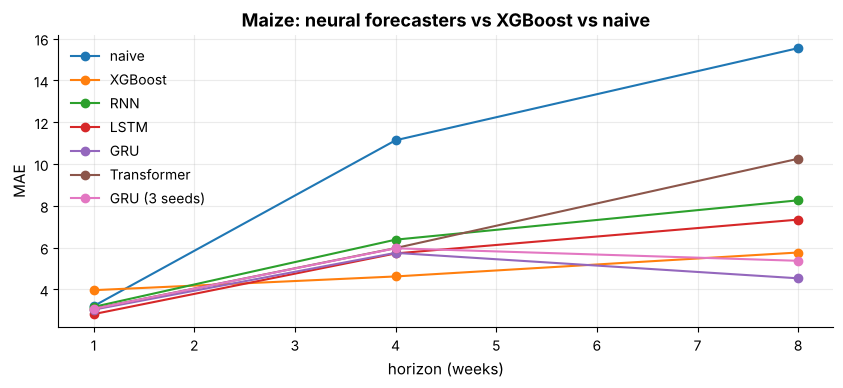

In [10]:
mae_h = pd.DataFrame({n: scores_by_horizon(w)["MAE"] for n, w in wf.items()}).rename_axis("horizon (weeks)")
print(f"{wf['naive'].origin.nunique()} forecast origins. MAE by horizon:")
display(mae_h.round(2))
print("Skill vs naive (1 - MAE/MAE_naive):")
display((1 - mae_h.div(mae_h["naive"], axis=0)).drop(columns="naive").round(2))
mae_h.plot(marker="o", figsize=(10, 3.8), title="Maize: neural forecasters vs XGBoost vs naive"); plt.ylabel("MAE"); plt.show()

### 🧠 Reading the tournament
- **All neural nets beat naive at h = 4 and h = 8** (by roughly 35–70 %): they learned the seasonality and driver effects from raw sequences, with *no hand-crafted lag features*. At h = 1 they roughly tie with naive.
- **XGBoost on engineered features is still extremely competitive** (often best). That's the pattern the literature reports on small single-series data.
- **Single-seed neural results jump around** between horizons and architectures (compare the GRU at h = 8 across settings); the 3-seed ensemble is steadier. With only 10 origins, treat small differences as noise.
- The plain RNN is not hopeless here (it can still learn from the recent weeks, and the seasonal Fourier inputs hand it the calendar directly), but gated nets are the safer default for long windows.

## 8 · Seeds: the hidden source of variance
The same network trained twice with different random seeds gives different forecasts. Let's quantify it on one split (see Problem 7.4 for your own version):

In [11]:
r = evaluate_split(mz, "lstm", h=8, seeds=(0, 1, 2, 3, 4))
m = np.array(r["per_seed_mae"])
print("LSTM, h = 8; MAE per seed:", m.round(2))
print(f"mean ± std = {m.mean():.2f} ± {m.std():.2f}   |   5-seed ensemble = {r['ens_mae']:.2f}   |   naive = {r['naive_mae']:.2f}")

LSTM, h = 8; MAE per seed: [7.92 7.98 8.24 8.03 7.59]
mean ± std = 7.95 ± 0.21   |   5-seed ensemble = 7.24   |   naive = 14.22


## 9 · Practical deep-learning checklist for forecasting

1. **Baselines first** (naive, seasonal naive, ETS/ARIMA, XGBoost). A neural net has to *earn* its complexity.
2. **Windows + chronological split.** Fit scalers on training windows only. Never evaluate on shuffled data.
3. **Scale-free targets/features** (returns, ratios). Neural nets extrapolate poorly too.
4. **Small networks, strong regularisation** (dropout, weight decay, early stopping) when you have ~hundreds of windows.
5. **Average several seeds.** Report mean ± std across seeds.
6. **Same walk-forward protocol** for every model class. Same origins, same horizons, same metric.
7. **Consider a *global* model**: one network trained across *many* commodities/markets (add an embedding or one-hot for the commodity). This is where deep learning starts to pay off, and a natural extension for your capstone.
8. **Keep exogenous inputs honest**: only information known at the origin.

## 🧩 Practice problems
`evaluate_split` (trains once, evaluates on all later origins) makes experiments fast. Each call takes a few seconds.

### 🧩 Problem 7.1 · Count the windows  ·  🟢 Easy

(a) A series has `T = 300` observations. With input length `L = 26` and horizon `H = 4`, how many training windows can you cut (no warm-up NaNs)?
  (b) Now use the real code: build windows for **rice** with `make_windows(sf, lp, L=52, H=8)` and report `N`. Store (b) in `n_windows` and print the shape of `X`.

<details><summary>💡 Hint 1</summary>

A window needs `L` past observations *and* `H` future ones, so the last usable origin is `T − H` and the first is `L − 1` (0-based).

</details>

<details><summary>💡 Hint 2</summary>

(a) = `T − L − H + 1`.

</details>

<details><summary>💡 Hint 3</summary>

(b) `sf, lp = make_step_features(rice)`; `X, Y, org = make_windows(sf, lp, 52, 8)`; `len(X)`.

</details>

In [12]:
rice = load_weekly('rice')
n_windows = None
# YOUR CODE HERE
check('windows for rice (L=52, H=8)', n_windows, 556)

⏳ windows for rice (L=52, H=8): not answered yet (replace the `None` with your answer)


### 🧩 Problem 7.2 · Count parameters before you run  ·  🟡 Medium

A recurrent layer with input size `F` and hidden size `H` has `H(F+H)+2H` weights per 'gate block'. RNN has **1** block, GRU **3**, LSTM **4**; add a linear head `H×8+8`.
  Predict (on paper!) the total trainable parameters of RNN, GRU and LSTM for `F = 9`, `H = 64`, then verify with `count_params(build_model(...))`.
  Store the LSTM count in `lstm_params`.

<details><summary>💡 Hint 1</summary>

Block size for F = 9, H = 64: `64 × (9 + 64) + 2 × 64 = 4800`.

</details>

<details><summary>💡 Hint 2</summary>

Head: `64 × 8 + 8 = 520`.

</details>

<details><summary>💡 Hint 3</summary>

LSTM = 4 × 4800 + 520; GRU = 3 × 4800 + 520; RNN = 4800 + 520.

</details>

In [13]:
lstm_params = None
# YOUR CODE HERE
check('LSTM parameters', lstm_params, 19720)

⏳ LSTM parameters: not answered yet (replace the `None` with your answer)


### 🧩 Problem 7.3 · Tune a GRU the honest way  ·  🟡 Medium

On **onion** use `evaluate_split(onion, 'gru', h=4, hidden=..., dropout=...)` for `hidden ∈ {16, 32, 64}` and `dropout ∈ {0.0, 0.2}`.
  Choose the configuration with the lowest **validation loss** (`min(result['best_val'])`), *not* the lowest test MAE, then report its test MAE and the naive MAE.
  Why is picking by test MAE a mistake?

<details><summary>💡 Hint 1</summary>

`r = evaluate_split(onion, 'gru', h=4, hidden=32, dropout=0.2)`; keys: `best_val` (list per seed), `per_seed_mae`, `naive_mae`.

</details>

<details><summary>💡 Hint 2</summary>

Loop with `itertools.product`; store `(hidden, dropout, best_val[0], per_seed_mae[0])`.

</details>

<details><summary>💡 Hint 3</summary>

Selecting on the test set means the test set is no longer unseen: the reported error is optimistically biased.

</details>

In [14]:
import itertools
onion = load_weekly('onion')
# YOUR CODE HERE

### 🧩 Problem 7.4 · How noisy is a neural network? Seeds and ensembles  ·  🟡 Medium

Train an **LSTM** on **maize** with seeds `0, 1, 2, 3, 4` via `evaluate_split(mz, 'lstm', h=8, seeds=(0, 1, 2, 3, 4))`. Report the mean and standard deviation of the per-seed test MAE,
  the MAE of the **averaged** (ensemble) forecast, and the naive MAE. What does the spread tell you about trusting a single run?

<details><summary>💡 Hint 1</summary>

The result dict has `per_seed_mae` (list of 5) and `ens_mae` (MAE of the mean forecast).

</details>

<details><summary>💡 Hint 2</summary>

`np.mean`, `np.std` of `per_seed_mae`.

</details>

<details><summary>💡 Hint 3</summary>

An ensemble averages out run-to-run randomness (initialisation, mini-batch order).

</details>

In [15]:
mz = load_weekly('maize')
# YOUR CODE HERE

### 🧩 Problem 7.5 · How much history does the network need?  ·  🔴 Challenge

For a **GRU** on **maize** (h = 8, `seeds=(0, 1, 2)`), vary the input window length `L ∈ {13, 26, 52, 78}` using `evaluate_split(..., L=L)`.
  Compare the ensemble MAE and the naive MAE for each `L` (the *test targets are identical across L*, so the comparison is fair; why?). Is longer always better? Relate your finding to the 52-week seasonal cycle.

<details><summary>💡 Hint 1</summary>

`evaluate_split(mz, 'gru', h=8, L=L, seeds=(0, 1, 2))['ens_mae']`.

</details>

<details><summary>💡 Hint 2</summary>

Test origins are all weeks after `t0 = 469`; `L` only changes how far *back* each window looks, not which targets are evaluated.

</details>

<details><summary>💡 Hint 3</summary>

A 13- or 26-week window cannot 'see' last year's same season; a ≥ 52-week window can (and also includes the lagged rainfall effect).

</details>

In [16]:
mz = load_weekly('maize')
# YOUR CODE HERE

## ✅ Recap
- Sequence models consume **windows** shaped (batch, time, features); split chronologically, shuffle only *within* training.
- **RNN** = hidden state recurrence; vanishes over long ranges. **LSTM/GRU** = gates + additive memory → long-range learning.
- **Transformer** = self-attention (+ positional information); parallel, powerful, data-hungry.
- Train with **standardisation, Huber loss, AdamW, dropout, clipping, early stopping on a chronological slice**.
- On small single-series data, neural nets are *competitive, not magical*; **ensembles of seeds** tame their variance, and **XGBoost/ETS remain strong baselines**.

### ⚠️ Common mistakes
1. Scaling with statistics from the full dataset (leakage).
2. Random validation splits for early stopping (use the most recent slice).
3. Reporting a single lucky seed.
4. Giant networks on tiny data.
5. Skipping the baselines.

### 🔮 Next lesson
Time to put everything together. **Lesson 8** is the guided **practical assignment**: eight steps from raw price plots to a fair model comparison on agricultural market prices.